<a href="https://colab.research.google.com/github/Albertoromero-01/Modelado-Y-Simulaci-n-De-Sistemas-Mecatr-nicos/blob/main/archivos/Actividad5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ACTIVIDAD FUNDAMENTAL 5: Simulación de un sistema a partir de ecuaciones de Euler-Lagrange

In [7]:
# ACTIVIDAD FUNDAMENTAL 5: Simulación de un sistema a partir de ecuaciones de Euler-Lagrange
# Nombre - Matrícula:
# José Alberto Romero Francisco-2000506
# Daniel Alessandro Campa Torres-2095970
# Brian Fabian Beyer Lopez-2096622
# Angel Sebastian Mendoza-Bolaños 2103541
# Hector Eduardo Nava Escobedo-2177703
# Andre Nicolas Almonte Galvan-2177929

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# -----------------------------------------------------------------
# 1. Definición de la Ecuación Dinámica (Método de Euler-Lagrange)
# -----------------------------------------------------------------

def f(t, x):
    # Parámetros del modelo proporcionados en la actividad
    Ir = 0.16     # Momento de inercia (kg*m^2)
    m = 5.0       # Masa total del mecanismo (kg)
    g = 9.81      # Aceleración de la gravedad (m/s^2)
    lc = 0.01     # Distancia al centro de masa (m)
    b = 0.14      # Coeficiente de fricción viscosa (Nms/rad)
    fc = 0.45     # Coeficiente de fricción de Coulomb (Nm)

    # Vector de Estados
    q = x[0]      # Posición articular (rad)
    qp = x[1]     # Velocidad articular (rad/s)

    # Torque de entrada (motor)
    tau_motor = tau(t)

    # Modelo de Fricción de Coulomb (Aproximación suave usando tanh como el ejemplo del inge)
    friccion_coulomb = fc * np.tanh(100000 * qp)

    # Cálculo de la aceleración articular (qpp) despejada de Euler-Lagrange
    qpp = (1 / Ir) * (tau_motor - m * g * lc * np.sin(q) - b * qp - friccion_coulomb)

    # Vector de salida (Derivadas del estado)
    dxdt = [qp, qpp]
    return dxdt

# Función para el Torque de Entrada (Siguiendo la forma del ejemplo)
def tau(t):
    # Se aplica un torque sinusoidal con amplitud de 1.5 Nm
    return 1.5 * np.sin(t)

In [2]:
# -----------------------------------------------------------------
# 2. Configuración y Resolución de la Simulación
# -----------------------------------------------------------------

# Parámetros de simulación
ti = 0.0     # Tiempo inicial (s)
tf = 10.0    # Tiempo final (s)
h = 0.0025   # Tamaño de paso de muestreo

# Vector de tiempo para la evaluación
ts = np.arange(ti, tf, h)

# Condiciones iniciales de los estados (X1 = 0, X2 = 0)
q0 = 0.0     # Posición inicial (0 rad)
qp0 = 0.0    # Velocidad inicial (0 rad/s)
x0 = [q0, qp0]

# Resolución numérica usando solve_ivp (equivalente a ode45)
sol = solve_ivp(f, [ti, tf], x0, t_eval=ts)

# Extracción de resultados
t = sol.t
posicion = sol.y[0]
velocidad = sol.y[1]

# Conversión de radianes a grados para visualización
posicion_grados = np.rad2deg(posicion)
velocidad_grados = np.rad2deg(velocidad)

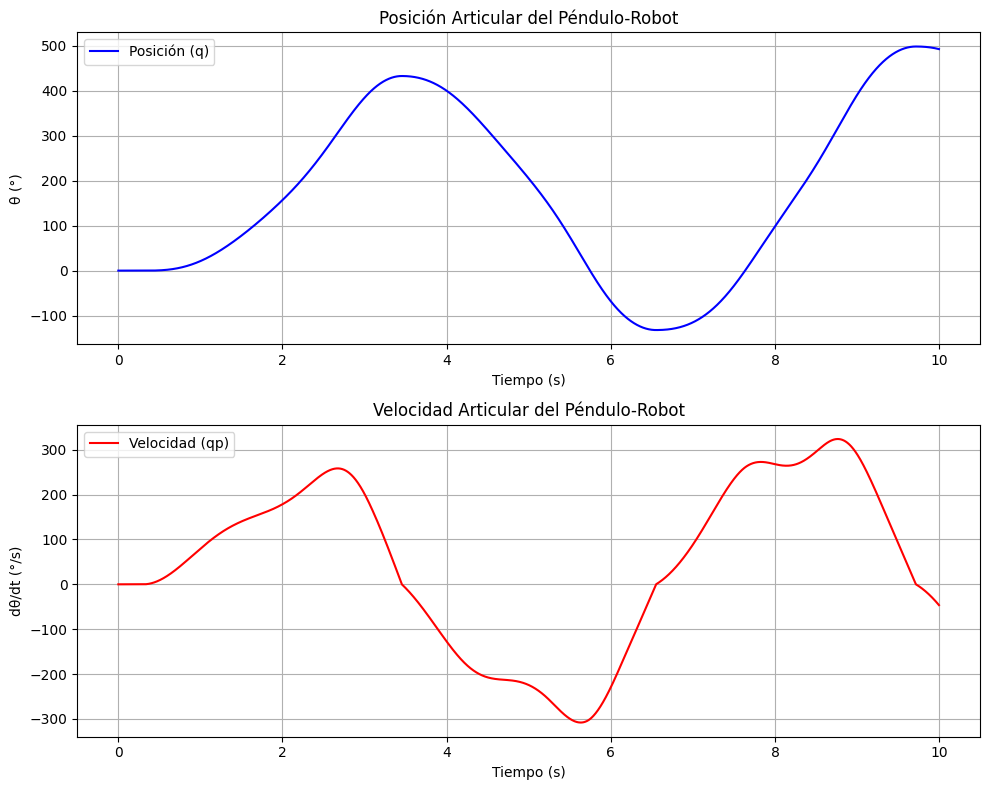

In [3]:
# -----------------------------------------------------------------
# 3. Gráficas de Resultados
# -----------------------------------------------------------------

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

# Gráfica de Posición Articular
ax1.plot(t, posicion_grados, 'b-', label='Posición (q)')
ax1.set_xlabel('Tiempo (s)')
ax1.set_ylabel('θ (°)')
ax1.set_title('Posición Articular del Péndulo-Robot')
ax1.grid(True)
ax1.legend()

# Gráfica de Velocidad Articular
ax2.plot(t, velocidad_grados, 'r-', label='Velocidad (qp)')
ax2.set_xlabel('Tiempo (s)')
ax2.set_ylabel('dθ/dt (°/s)')
ax2.set_title('Velocidad Articular del Péndulo-Robot')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

### Conclusión Grupal

En esta práctica logramos modelar y simular con éxito el comportamiento dinámico de un péndulo-robot de 1 GDL mediante la formulación de Euler-Lagrange. A partir de las gráficas de comportamiento obtenidas, se pueden destacar los siguientes puntos clave:

1. **Efecto de las Fuerzas No Lineales:** La dinámica del péndulo se encuentra fuertemente afectada por el término gravitacional ($mg l_c \sin(\theta)$). Esto se observa claramente en la respuesta no lineal de la posición y de la velocidad, las cuales, a pesar de estar excitadas por un torque puramente senoidal, muestran deformaciones y desfases debido a la influencia constante de la gravedad según la orientación del eslabón.
2. **Mitigación del Chattering Numérico:** El uso de una aproximación continua para la fricción de Coulomb empleando la función tangente hiperbólica ($\tanh(\alpha \dot{\theta})$) demostró ser una solución excelente en la práctica de simulación. Evitó por completo las discontinuidades bruscas y los problemas de convergencia (el clásico "chattering") que genera la función signo convencional en los solucionadores numéricos como `solve_ivp`.
3. **Amortiguamiento del Sistema:** La combinación de la fricción viscosa ($b$) y la fricción seca o de Coulomb ($f_c$) actúa limitando los picos de velocidad articular. Es evidente cómo el sistema disipa energía, evitando que las oscilaciones de posición diverjan ante la entrada senoidal de torque continuo.

En conclusión, esta actividad nos permitió validar de forma práctica la importancia de un buen modelado matemático. Las herramientas de simulación numérica no solo nos ayudan a predecir el comportamiento real de un manipulador mecánico antes de su construcción física, sino que también nos enfrentan a retos de simulación como el tratamiento numérico de las fricciones y discontinuidades físicas del sistema.

### Referencias Consultadas
- Spong, M. W., Hutchinson, S., & Vidyasagar, M. (2005). *Robot Modeling and Control*. Wiley.
- Ogata, K. (2010). *Modern Control Engineering*. Prentice Hall.